# 03 · Evaluation and model selection

All numbers come from `artifacts/metrics/` written by `scripts/run_experiments.py` (3 × stratified group 5-fold CV;
out-of-fold predictions; 95% CIs from a cluster bootstrap that resamples capture groups).

In [1]:
import sys, os, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "configs" / "default.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("GLOG_minloglevel", "2")
warnings.filterwarnings("ignore", category=UserWarning)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
from salat_vision.config import get_config
from salat_vision.viz import apply_style
apply_style()
cfg = get_config()
print("project root:", ROOT)

project root: /home/user/Shalat-Postures-Detection


In [2]:
cvr = json.loads((ROOT / "artifacts/metrics/cv_results.json").read_text())
cmp = pd.read_csv(ROOT / "artifacts/metrics/model_comparison.csv")
cols = ["model", "family", "crop_macro_f1", "crop_macro_f1_ci_lo", "crop_macro_f1_ci_hi", "crop_accuracy",
        "image_macro_f1", "image_accuracy", "abstain_rate", "ece"]
cmp[cols].sort_values("crop_macro_f1", ascending=False).round(3)

,model,family,crop_macro_f1,crop_macro_f1_ci_lo,crop_macro_f1_ci_hi,crop_accuracy,image_macro_f1,image_accuracy,abstain_rate,ece
10,fusion_pose_cnn,Fusion,0.795,0.684,0.900,0.833,0.679,0.721,0.00,0.183
2,pose_logreg,Pose,0.740,0.627,0.869,0.783,0.655,0.694,0.00,0.108
5,pose_mlp,Pose,0.706,0.598,0.830,0.758,0.619,0.676,0.00,0.142
8,cnn_ft_mobilenet_v3_large,CNN,0.649,0.514,0.760,0.700,0.599,0.631,0.00,0.088
6,cnn_probe_mobilenet_v3_large,CNN,0.630,0.465,0.748,0.692,0.660,0.712,0.00,0.097
4,pose_random_forest,Pose,0.629,0.511,0.752,0.667,0.561,0.631,0.00,0.051
3,pose_svm_rbf,Pose,0.616,0.518,0.716,0.683,0.549,0.604,0.00,0.118
9,cnn_ft_resnet18,CNN,0.579,0.483,0.700,0.658,0.556,0.622,0.00,0.022
1,pose_rules,Pose,0.553,0.381,0.715,0.525,0.461,0.432,0.15,0.200
7,cnn_probe_resnet18,CNN,0.553,0.413,0.734,0.633,0.531,0.586,0.00,0.088


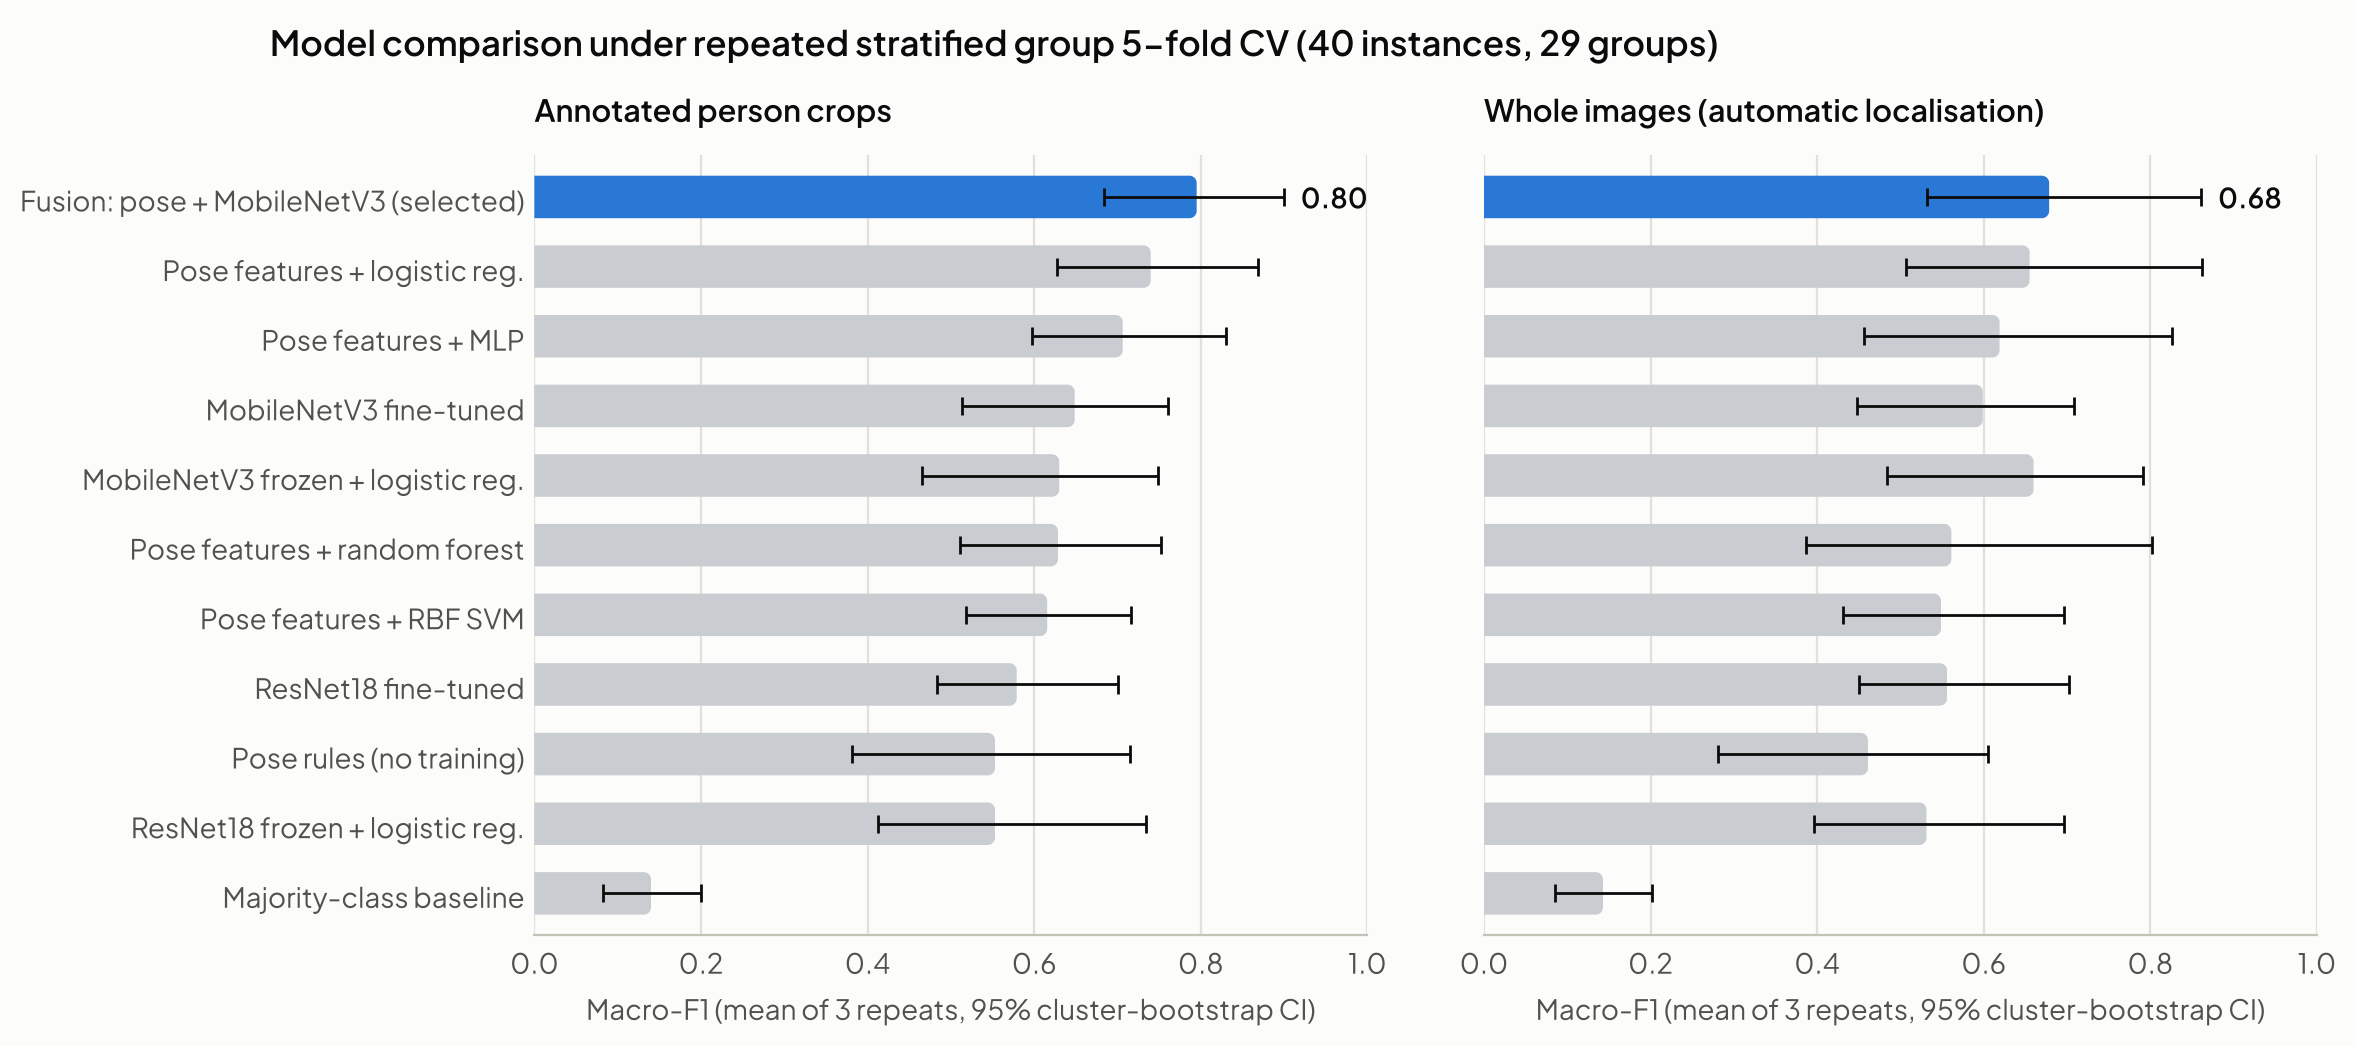

In [3]:
display(Image(str(ROOT / "artifacts/figures/model_comparison.png"), width=980))

## Selected model — per-class performance and confusions

fusion_pose_cnn | crop macro-F1 0.795 [0.684, 0.900] | image macro-F1 0.679 [0.532, 0.861]


,precision,recall,f1,support
qiyam,0.878,1.000,0.935,36.0
ruku,0.833,0.556,0.667,18.0
sujud,0.837,1.000,0.911,36.0
julus,0.750,0.600,0.667,30.0


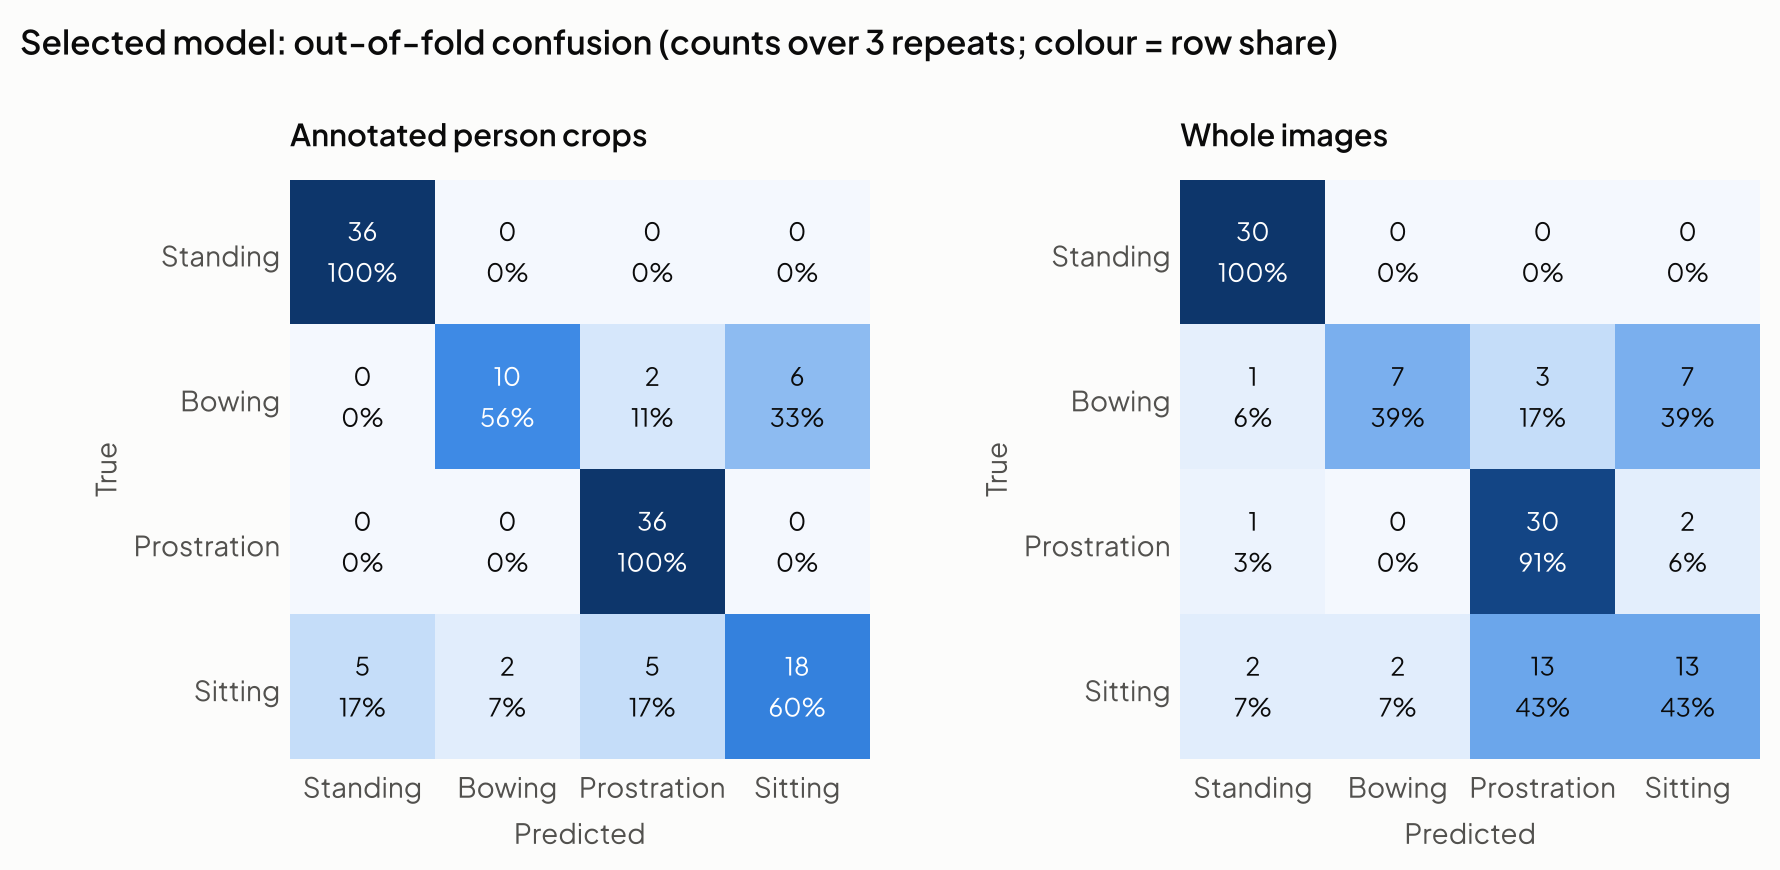

In [4]:
sel = cfg["final_model"]["cv_model_key"]
e = cvr["models"][sel]
print(sel, "| crop macro-F1 %.3f [%.3f, %.3f]" % (e["crop"]["macro_f1_mean"], *e["crop"]["macro_f1_ci95"]),
      "| image macro-F1 %.3f [%.3f, %.3f]" % (e["image"]["macro_f1_mean"], *e["image"]["macro_f1_ci95"]))
display(pd.DataFrame(e["crop"]["pooled"]["per_class"]).T.round(3))
display(Image(str(ROOT / "artifacts/figures/confusion_matrix.png"), width=860))

## Calibration

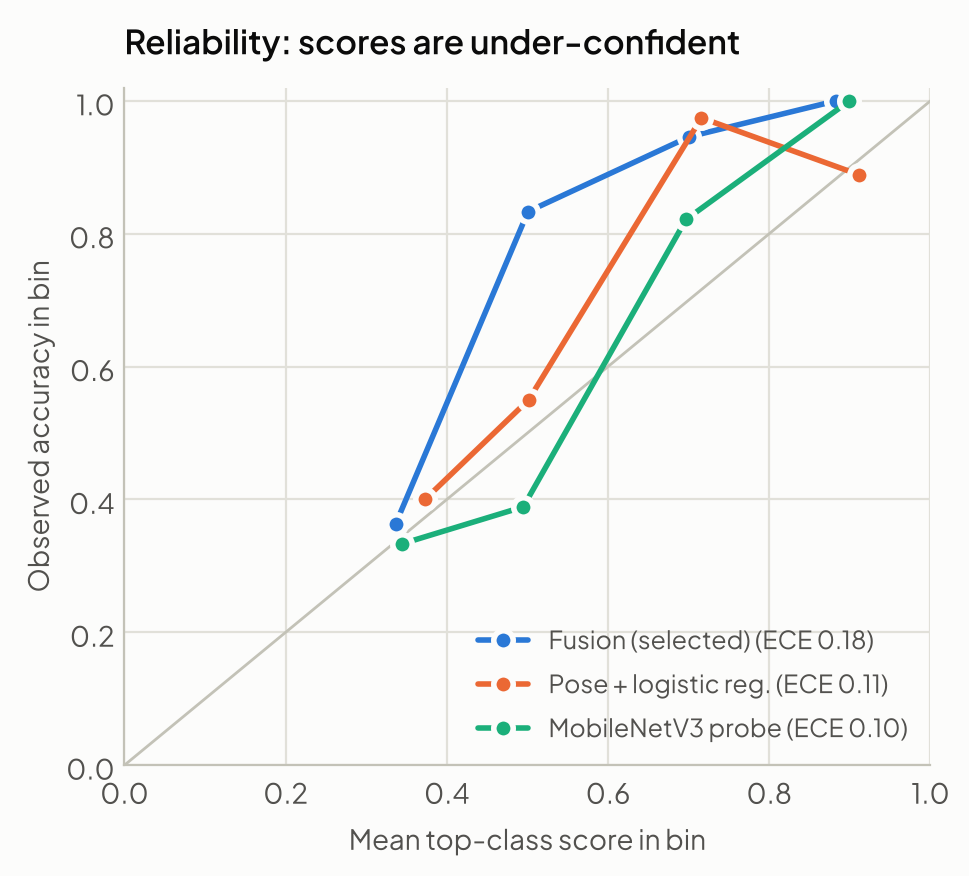

,lo,hi,n,accuracy,confidence
0,0.0,0.2,0,NaN,NaN
1,0.2,0.4,22,0.363636,0.336637
2,0.4,0.6,24,0.833333,0.500715
3,0.6,0.8,37,0.945946,0.700598
4,0.8,1.0,37,1.000000,0.882884


In [5]:
display(Image(str(ROOT / "artifacts/figures/calibration_reliability.png"), width=480))
pd.DataFrame(e["crop"]["calibration"]["bins"])

The fused scores are **under-confident** (accuracy above the score in every populated bin). Averaging two models and
strong L2 regularisation both shrink scores. Consequence for the product: the "uncertain" flag (score < 0.55) is
conservative. Scores are shown as model confidence, never as calibrated probabilities.

## Error analysis

In [6]:
oof = pd.read_csv(ROOT / "artifacts/metrics/oof_predictions.csv")
o = oof[(oof.model == sel) & (oof.view == "crop")]
err = o[o.true != o.pred].groupby(["id", "true", "pred"]).size().rename("times_wrong (of 3)").reset_index()
img = pd.read_csv(ROOT / "artifacts/metrics/dataset_images.csv").set_index("image_id")
err["source"] = err["id"].str.split("#").str[0].map(img["source_kind"])
err.sort_values("times_wrong (of 3)", ascending=False)

,id,true,pred,times_wrong (of 3),source
7,ruku109#0,ruku,julus,3,named series (ruku)
5,ck2or3u694ynn0757ptzgbv8t#0,julus,qiyam,3,web (Labelbox export)
3,7#0,julus,sujud,3,numbered photo
10,ruku26#0,ruku,julus,2,named series (ruku)
4,SittingMO56#0,julus,ruku,2,named series (sittingmo)
1,6#0,julus,qiyam,2,numbered photo
0,23#0,julus,sujud,1,numbered photo
2,6#0,julus,sujud,1,numbered photo
6,ck2ygl8aj78s5072595cehoma#0,ruku,sujud,1,web (Labelbox export)
8,ruku194#0,ruku,julus,1,named series (ruku)


In [7]:
from salat_vision.data.dataset import build_index
from salat_vision.data.voc import load_image_rgb
from salat_vision.features.pose import crop_with_padding
from salat_vision.privacy import Anonymizer
idx = build_index(cfg=cfg); li = idx.labeled_instances.set_index("instance_id")
anon = Anonymizer(cfg.path("pretrained_dir"))
worst = err.sort_values("times_wrong (of 3)", ascending=False).drop_duplicates("id").head(6)
fig, axes = plt.subplots(1, len(worst), figsize=(2.6 * len(worst), 3.2))
for ax, r in zip(np.atleast_1d(axes), worst.itertuples()):
    row = li.loc[r.id]; box = (row.xmin, row.ymin, row.xmax, row.ymax)
    blurred, _ = anon(load_image_rgb(idx.dataset_dir / row.file), [box])
    ax.imshow(crop_with_padding(blurred, box, 0.15)[0]); ax.set_axis_off()
    ax.set_title(f"true {r.true}\npred {r.pred}", fontsize=9)
anon.close(); fig.suptitle("Most frequent errors (faces blurred)", x=0.01, ha="left"); plt.show()

## Does the model lean on capture source? (shortcut check)

In [8]:
o2 = o.copy(); o2["source"] = o2["id"].str.split("#").str[0].map(img["source_kind"])
o2["web"] = np.where(o2.source.str.startswith("web"), "web (Labelbox)", "own captures / video frames")
o2.assign(correct=o2.true == o2.pred).groupby(["web", "true"]).correct.agg(["mean", "size"]).round(2)

mean  size
web                         true             
own captures / video frames julus  0.62    24
                            qiyam  1.00     9
                            ruku   0.42    12
                            sujud  1.00    12
web (Labelbox)              julus  0.50     6
                            qiyam  1.00    27
                            ruku   0.83     6
                            sujud  1.00    24

## Localisation (end-to-end view)

In [9]:
loc = pd.read_csv(ROOT / "artifacts/metrics/localization_eval.csv")
print(loc.loc_source.value_counts().to_dict(), "| IoU>=0.5 with an annotated box:", (loc.loc_best_iou >= 0.5).mean().round(3))
loc[loc.loc_best_iou < 0.5][["image_id", "label", "loc_source", "loc_best_iou", "pose_detected"]]

{'detector': 30, 'pose': 5, 'full_image': 2} | IoU>=0.5 with an annotated box: 0.919


,image_id,label,loc_source,loc_best_iou,pose_detected
31,ruku26,ruku,full_image,0.156813,False
33,sujud112,sujud,pose,0.247576,True
36,sujud77,sujud,full_image,0.196940,False


## Runtime

Intel(R) Xeon(R) Processor @ 2.10GHz | 4 vCPU | 11.94 frames/s


,n,mean_ms,median_ms,p95_ms,min_ms
localize,111.0,42.04,36.63,70.94,29.22
pose,111.0,32.28,34.91,42.84,10.35
pose_classifier,111.0,1.18,1.31,1.85,0.00
image_model,111.0,8.20,8.04,10.17,5.92
total,111.0,83.76,81.00,113.26,53.91


,detection rate,mean ms,MB
lite,0.800,29.56,5.8
full,0.850,33.57,9.4
heavy,0.825,69.41,30.7


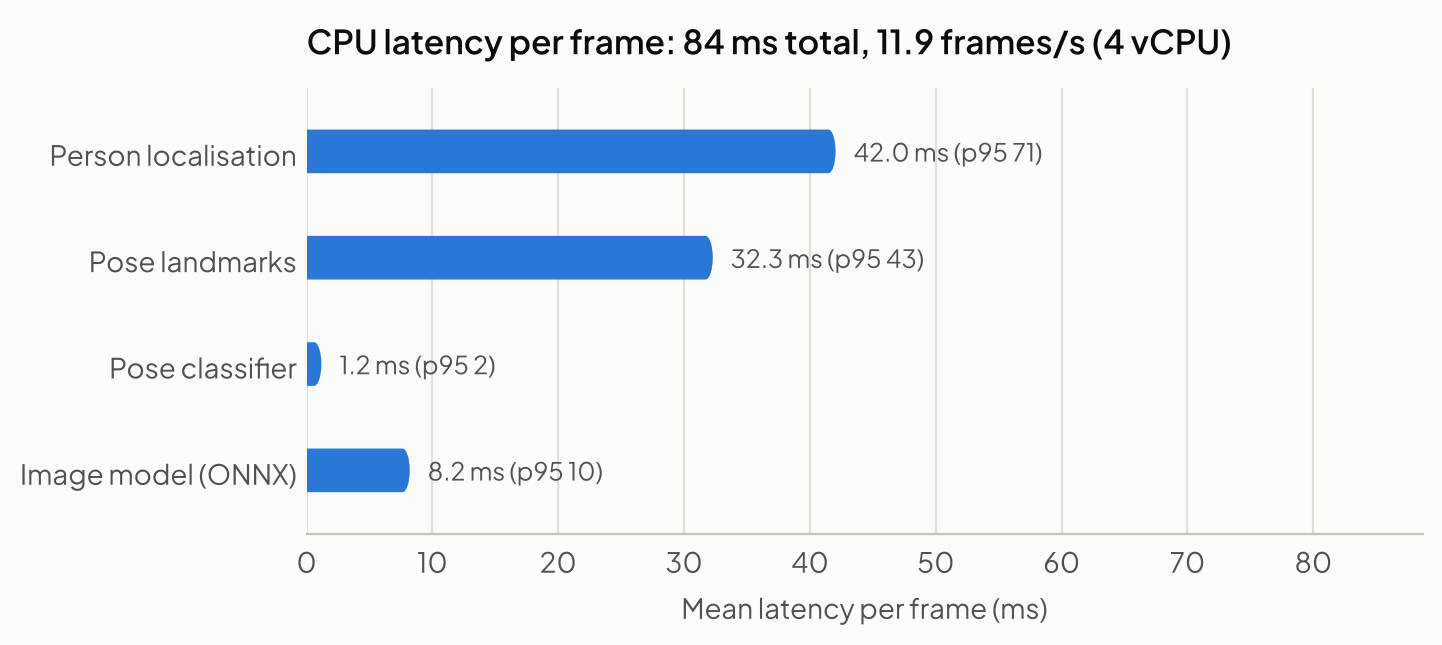

In [10]:
rt = json.loads((ROOT / "artifacts/metrics/runtime_benchmark.json").read_text())
pv = json.loads((ROOT / "artifacts/metrics/pose_variant_benchmark.json").read_text())
print(rt["hardware"]["cpu"], "|", rt["hardware"]["logical_cores"], "vCPU |", rt["throughput_fps"], "frames/s")
display(pd.DataFrame(rt["stages"]).T)
display(pd.DataFrame({v: {"detection rate": d["detection_rate"], "mean ms": d["latency"]["mean_ms"], "MB": d["size_mb"]} for v, d in pv["variants"].items()}).T)
display(Image(str(ROOT / "artifacts/figures/benchmark_chart.png"), width=640))

## Selection

* **Selected:** the pre-registered fusion of pose logistic regression and the frozen MobileNetV3 probe — highest mean
  macro-F1 on both views (0.80 crops, 0.68 images) and the lowest variance across repeats; chosen before results, so
  no selection bias; its components are fast (≈10 ms together after pose estimation).
* **Caveat:** confidence intervals of the top models overlap; with 29 independent groups the ranking is suggestive,
  not conclusive. The full dataset (and real prayer videos) are needed for a definitive comparison.
* **Rejected:** fine-tuned CNNs (overfit, ~100x slower to train, no gain), ResNet18 (worse than MobileNetV3 in every
  setting), training-free rules (useful baseline, but abstain when no pose is found).